In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cwfc.baselines import decay_forecast, mean_forecast, persistence_forecast
from cwfc.evaluation import backtest
from cwfc.interval import add_interval, residual_quantiles
from cwfc.split import split_holdout
from cwfc.targets import build_targets

logging.basicConfig(level=logging.INFO)
readings = pd.read_csv("../challenge_data/vm_cpu_readings.csv.gz")
targets = build_targets(readings)
train, holdout_timestamps = split_holdout(targets)
TARGET = "aggregate_cpu_utilization"
template = pd.DataFrame({"timestamp": holdout_timestamps})

# The single look at the holdout values. The model was fixed before this cell.
actual = targets.set_index("timestamp").loc[holdout_timestamps.to_numpy(), TARGET].to_numpy()

INFO:cwfc.targets:Dropped 0 of 1340000 rows


In [2]:
forecasts = {
    "decay": decay_forecast(train, template, TARGET).to_numpy(),
    "persistence": persistence_forecast(train, template, TARGET).to_numpy(),
    "mean (all)": mean_forecast(train, template, TARGET).to_numpy(),
}
rows = []
for name, f in forecasts.items():
    err = actual - f
    rows.append({"model": name, "mae": np.abs(err).mean(), "rmse": np.sqrt((err ** 2).mean()), "bias": err.mean()})
summary = pd.DataFrame(rows).set_index("model")
summary["vs_persistence"] = 1 - summary["mae"] / summary.loc["persistence", "mae"]
summary.round(3)

,mae,rmse,bias,vs_persistence
model,,,,
decay,0.154,0.184,-0.124,-0.048
persistence,0.147,0.185,0.104,0.000
mean (all),0.175,0.210,-0.145,-0.189


Finding: On the holdout, persistence has the lowest MAE (0.147), the decay model is 4.8% behind (0.154, RMSE about the same: 0.184 vs 0.185), and the mean is worst (0.175). The gap between decay and persistence (0.007) is well within the fold-to-fold variation seen in validation (std ~0.06), and the holdout is a single 24-step window, so this does not contradict the model choice made on 7 folds. The model is not changed after looking at the holdout.

Decay has a negative bias (−0.124): it over-forecasts because it pulls towards the training mean (9.41%), while the holdout level is lower (9.27%), closer to the last training value (9.17%).

Interval coverage: 0.792 | above upper: 0 | below lower: 5


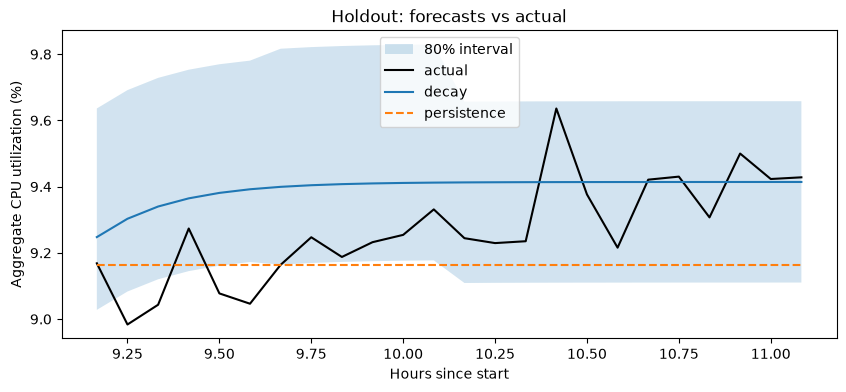

In [3]:
band = add_interval(pd.Series(forecasts["decay"]), residual_quantiles(backtest(train, decay_forecast, TARGET)))
inside = (actual >= band["lower"]) & (actual <= band["upper"])
print("Interval coverage:", round(inside.mean(), 3),
      "| above upper:", int((actual > band["upper"]).sum()),
      "| below lower:", int((actual < band["lower"]).sum()))

hours = holdout_timestamps.to_numpy() / 3600
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(hours, band["lower"], band["upper"], alpha=0.2, label="80% interval")
ax.plot(hours, actual, color="black", label="actual")
ax.plot(hours, forecasts["decay"], label="decay")
ax.plot(hours, forecasts["persistence"], linestyle="--", label="persistence")
ax.set_xlabel("Hours since start")
ax.set_ylabel("Aggregate CPU utilization (%)")
ax.set_title("Holdout: forecasts vs actual")
ax.legend()
plt.show()

Finding: The 80% interval covers 79.2% of holdout values, in line with its target. All 5 misses fall below the lower bound; the upper bound is never exceeded. Provisioning to the upper bound would have avoided under-provisioning in this window, at the cost of some unused capacity. With a single window, this should not be over-generalised.

In [4]:
vm_actual = targets.set_index("timestamp").loc[holdout_timestamps.to_numpy(), "active_vm_count"].to_numpy()
vm_forecast = decay_forecast(train, template, "active_vm_count").round().to_numpy()
print("active_vm_count MAE:", np.abs(vm_actual - vm_forecast).mean())

active_vm_count MAE: 0.0


Finding: active_vm_count stays at 10,000 in the holdout and the forecast is exactly 10,000 (MAE 0), as expected from the absence of churn in this curated subset.

In [5]:
steps = pd.DataFrame({"step": range(1, 25), "hour": hours, "actual": actual, "decay": forecasts["decay"]})
steps["error"] = steps["actual"] - steps["decay"]
top = steps["actual"] >= steps["actual"].quantile(0.75)
print("Decay MAE in the highest quarter:", round(steps.loc[top, "error"].abs().mean(), 3),
      "| rest:", round(steps.loc[~top, "error"].abs().mean(), 3))
steps.round(3)

Decay MAE in the highest quarter: 0.059 | rest: 0.185


,step,hour,actual,decay,error
0,1,9.167,9.168,9.248,-0.079
1,2,9.250,8.984,9.303,-0.319
2,3,9.333,9.043,9.340,-0.297
3,4,9.417,9.274,9.365,-0.091
4,5,9.500,9.078,9.381,-0.304
5,6,9.583,9.046,9.392,-0.346
6,7,9.667,9.164,9.399,-0.236
7,8,9.750,9.247,9.404,-0.157
8,9,9.833,9.188,9.408,-0.220
9,10,9.917,9.232,9.410,-0.177


Finding: The largest errors come from the dip at steps 2–6 (actual ~9.0–9.1%), not from the highest values: decay MAE is 0.059 in the highest quarter of holdout values and 0.185 elsewhere.